# Food Orders: Data Understanding, Transformation & Validation
## Student practical assignment

#### **Name:** Akurati Joohi Hanuma

####  **Batch:** 1 

#### **Dataset:** food_orders.csv


---
## Task 1 — Load and understand the dataset

### Task 1.1 — Import the Python libraries

Import the tools used to load, inspect, transform, and visualize the data.

In [1]:
# Task 1.1 — Import the Python libraries
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Task 1.2 — Load food_orders.csv into raw_df

Read all columns as text first so the original source representation is preserved before inspecting or converting types.

In [2]:
# Task 1.2 — Load food_orders.csv into raw_df
# Keep source values as text initially; missing cells remain missing.
CSV_PATH = Path("food_orders.csv")
if not CSV_PATH.exists():
    raise FileNotFoundError(f"Place food_orders.csv beside the notebook: {CSV_PATH.resolve()}")
raw_df = pd.read_csv(CSV_PATH, dtype="string")
print(f"Loaded {len(raw_df):,} rows and {raw_df.shape[1]} columns")

Loaded 1,010 rows and 14 columns


### Task 1.3 — Display first five, last five, and a random sample of five rows

Use a fixed random seed so the sample is repeatable when the notebook is rerun.

In [3]:
# Task 1.3 — Display first five, last five, and a random sample of five rows
# Preview the beginning, end, and a repeatable random sample of the source.
display(raw_df.head(5))
display(raw_df.tail(5))
display(raw_df.sample(n=min(5, len(raw_df)), random_state=42))

,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914.0,0.0,Credit Card,5% on App,150.0,47.0,0.0,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.0,40.0,Digital Wallet,10%,198.0,23.0,0.0,Cloudy,Mobile App
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.0,30.0,Cash on Delivery,15% New User,195.0,45.0,0.0,Humid,Mobile App
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,1463.0,<NA>,Cash on Delivery,<NA>,146.0,27.0,0.0,Rainy,Mobile App
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,1992.0,30.0,Cash on Delivery,50 off Promo,130.0,50.0,<NA>,Sunny,Mobile App


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
1005,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,<NA>,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App
1006,580,C8102,R2257,2024-01-03 08:46:06,2024-01-03 10:10:06,1045.0,40.0,Cash on Delivery,10%,137.0,13.0,0.0,Sunny,Partner App
1007,497,C9010,R2462,2024-02-04 13:07:32,2024-02-04 14:25:32,1125.0,0.0,Credit Card,10%,95.0,16.0,50.0,Cloudy,Partner App
1008,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App
1009,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,<NA>,50.0,50.0,150.0,Cloudy,Mobile App


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
629,630,C1716,R2905,2024-01-13 04:16:47,2024-01-13 06:09:47,<NA>,0.0,Cash on Delivery,5% on App,91.0,42.0,100.0,Rainy,Mobile App
788,789,C9659,R2778,2024-01-31 10:35:46,2024-01-31 12:07:46,714.0,40.0,Cash on Delivery,<NA>,178.0,25.0,150.0,Rainy,Partner App
684,685,C7254,R2538,2024-01-07 23:31:43,2024-01-08 01:04:43,204.0,40.0,Digital Wallet,<NA>,195.0,11.0,0.0,Cloudy,Mobile App
516,517,C8494,R2687,2024-01-23 05:41:17,2024-01-23 06:24:17,948.0,50.0,<NA>,<NA>,106.0,28.0,0.0,Sunny,Mobile App
529,530,C5268,R2697,2024-02-04 18:17:27,2024-02-04 18:51:27,1815.0,50.0,Cash on Delivery,15% New User,114.0,33.0,0.0,Sunny,Mobile App


### Task 1.4 — Display row/column counts, names, and data types

The initial source dtypes are strings by design; later cells parse dates and numeric values explicitly.

In [4]:
# Task 1.4 — Display row/column counts, names, and data types
# Show the source dimensions, field names, and current source dtypes.
print("Rows:", raw_df.shape[0])
print("Columns:", raw_df.shape[1])
print("Column names:", raw_df.columns.tolist())
display(raw_df.dtypes.rename("source dtype").to_frame())

Rows: 1010
Columns: 14
Column names: ['Order ID', 'Customer ID', 'Restaurant ID', 'Order Date and Time', 'Delivery Date and Time', 'Order Value', 'Delivery Fee', 'Payment Method', 'Discounts and Offers', 'Commission Fee', 'Payment Processing Fee', 'Refunds/Chargebacks', 'Weather Condition', 'Order Channel']


,source dtype
Order ID,string
Customer ID,string
Restaurant ID,string
Order Date and Time,string
Delivery Date and Time,string
Order Value,string
Delivery Fee,string
Payment Method,string
Discounts and Offers,string
Commission Fee,string


### Task 1.5 — Summarize numeric and categorical columns

Summarize the source before conversion, then show the likely numeric and categorical fields separately.

In [5]:
# Task 1.5 — Summarize numeric and categorical columns
# Summarize categorical/text source values as received.
display(raw_df.describe(include="all").T)

# Parse a temporary copy only for descriptive statistics; raw_df stays unchanged.
summary_df = raw_df.copy()
for col in ["Order Value", "Delivery Fee", "Commission Fee", "Payment Processing Fee", "Refunds/Chargebacks"]:
    summary_df[col] = pd.to_numeric(summary_df[col], errors="coerce")
print("Numeric financial-column summary:")
display(summary_df[["Order Value", "Delivery Fee", "Commission Fee", "Payment Processing Fee", "Refunds/Chargebacks"]].describe().T)
print("Categorical-column summary:")
display(raw_df[["Payment Method", "Discounts and Offers", "Weather Condition", "Order Channel"]].describe().T)

,count,unique,top,freq
Order ID,1010,1000,122,2
Customer ID,1010,947,C7949,3
Restaurant ID,1010,621,R2317,6
Order Date and Time,1010,1000,2024-02-05 05:55:15,2
Delivery Date and Time,1010,1000,2024-02-05 07:33:15,2
Order Value,969,746,291.0,5
Delivery Fee,960,5,40.0,207
Payment Method,960,3,Cash on Delivery,341
Discounts and Offers,768,4,10%,221
Commission Fee,970,151,95.0,13


Numeric financial-column summary:


,count,mean,std,min,25%,50%,75%,max
Order Value,969.0,1055.901961,529.534182,104.0,600.0,1041.0,1494.0,1995.0
Delivery Fee,960.0,28.625,16.927281,0.0,20.0,30.0,40.0,50.0
Commission Fee,970.0,127.042268,43.013345,50.0,90.25,128.0,164.0,200.0
Payment Processing Fee,959.0,29.895725,11.731583,10.0,20.0,30.0,40.0,50.0
Refunds/Chargebacks,970.0,27.886598,49.383898,0.0,0.0,0.0,50.0,150.0


Categorical-column summary:


,count,unique,top,freq
Payment Method,960,3,Cash on Delivery,341
Discounts and Offers,768,4,10%,221
Weather Condition,1010,4,Sunny,405
Order Channel,1010,3,Mobile App,693


### Task 1.6 — Describe each column and its expected data type

The descriptions below classify identifiers, timestamps, financial measures, and categories for the analysis.

In [6]:
# Task 1.6 — Describe each column and its expected data type
# Document the apparent meaning and expected analytical type of every source field.
column_guide = pd.DataFrame([
    ("Order ID", "Order/transaction identifier", "Identifier"),
    ("Customer ID", "Customer identifier", "Identifier"),
    ("Restaurant ID", "Restaurant identifier", "Identifier"),
    ("Order Date and Time", "Timestamp when the order was placed", "Datetime"),
    ("Delivery Date and Time", "Timestamp when delivery occurred", "Datetime"),
    ("Order Value", "Value of the food order", "Numeric / financial"),
    ("Delivery Fee", "Delivery fee amount", "Numeric / financial"),
    ("Payment Method", "Payment method/category", "Category"),
    ("Discounts and Offers", "Offer or discount description", "Category / text"),
    ("Commission Fee", "Platform commission amount", "Numeric / financial"),
    ("Payment Processing Fee", "Payment processing cost", "Numeric / financial"),
    ("Refunds/Chargebacks", "Refund or chargeback amount", "Numeric / financial"),
    ("Weather Condition", "Recorded weather category", "Category"),
    ("Order Channel", "Channel used to place the order", "Category"),
], columns=["Column", "Information represented", "Expected type"])
display(column_guide)

,Column,Information represented,Expected type
0,Order ID,Order/transaction identifier,Identifier
1,Customer ID,Customer identifier,Identifier
2,Restaurant ID,Restaurant identifier,Identifier
3,Order Date and Time,Timestamp when the order was placed,Datetime
4,Delivery Date and Time,Timestamp when delivery occurred,Datetime
5,Order Value,Value of the food order,Numeric / financial
6,Delivery Fee,Delivery fee amount,Numeric / financial
7,Payment Method,Payment method/category,Category
8,Discounts and Offers,Offer or discount description,Category / text
9,Commission Fee,Platform commission amount,Numeric / financial


**Task 1 observation:** One row represents a food-delivery order record. Order Value supports order-value analysis; the order and delivery timestamps support delivery-time analysis; payment fields identify payment mix; and Commission Fee, Delivery Fee, Payment Processing Fee, and Refunds/Chargebacks are inputs to the assignment's simplified platform-revenue measure.

## Task 2 — Perform a data-quality assessment

### Task 2.1 — Count missing values in each column

Count null values in the original source before making changes.

In [7]:
# Task 2.1 — Count missing values in each column
# Count missing source values by field.
missing_counts = raw_df.isna().sum()
display(missing_counts.rename("missing_count").to_frame())

,missing_count
Order ID,0
Customer ID,0
Restaurant ID,0
Order Date and Time,0
Delivery Date and Time,0
Order Value,41
Delivery Fee,50
Payment Method,50
Discounts and Offers,242
Commission Fee,40


### Task 2.2 — Calculate the percentage missing in each column

Calculate each missing count as a percentage of all source records.

In [8]:
# Task 2.2 — Calculate the percentage missing in each column
# Calculate source missingness percentages.
missing_percent = (raw_df.isna().mean() * 100).round(2)
display(missing_percent.rename("missing_percent").to_frame())

,missing_percent
Order ID,0.00
Customer ID,0.00
Restaurant ID,0.00
Order Date and Time,0.00
Delivery Date and Time,0.00
Order Value,4.06
Delivery Fee,4.95
Payment Method,4.95
Discounts and Offers,23.96
Commission Fee,3.96


### Task 2.3 — Count fully duplicated rows

Count complete row matches. This is different from repeated Order IDs, which are checked separately.

In [9]:
# Task 2.3 — Count fully duplicated rows
# Count full-row duplicate records without deleting anything yet.
print("Fully duplicated rows:", int(raw_df.duplicated().sum()))
display(raw_df.loc[raw_df.duplicated(keep=False)].sort_index())

Fully duplicated rows: 10


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
121,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,1438.0,0.0,Cash on Delivery,50 off Promo,51.0,<NA>,0.0,Cloudy,Mobile App
132,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,<NA>,50.0,50.0,150.0,Cloudy,Mobile App
155,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,1017.0,40.0,Cash on Delivery,5% on App,95.0,19.0,0.0,Rainy,Mobile App
196,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App
207,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,<NA>,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App
418,419,C2066,R2301,2024-01-27 18:49:41,2024-01-27 20:10:41,1857.0,30.0,Digital Wallet,<NA>,106.0,43.0,0.0,Sunny,Partner App
496,497,C9010,R2462,2024-02-04 13:07:32,2024-02-04 14:25:32,1125.0,0.0,Credit Card,10%,95.0,16.0,50.0,Cloudy,Partner App
570,571,C7819,R2393,2024-01-18 21:30:36,2024-01-18 23:17:36,605.0,40.0,Cash on Delivery,50 off Promo,96.0,23.0,0.0,Sunny,Mobile App
579,580,C8102,R2257,2024-01-03 08:46:06,2024-01-03 10:10:06,1045.0,40.0,Cash on Delivery,10%,137.0,13.0,0.0,Sunny,Partner App
830,831,C4530,R2105,2024-01-18 05:44:53,2024-01-18 07:13:53,689.0,40.0,Credit Card,5% on App,159.0,39.0,0.0,Cloudy,Mobile App


### Task 2.4 — Check repeated Order ID values before deciding what to remove

Repeated identifiers are evidence for investigation, not automatic proof of duplicate transactions.

In [10]:
# Task 2.4 — Check repeated Order ID values before deciding what to remove
# Report all source records whose Order ID occurs more than once.
repeated_id_mask = raw_df["Order ID"].duplicated(keep=False)
repeated_id_rows = raw_df.loc[repeated_id_mask].sort_values("Order ID")
print("Rows associated with repeated Order IDs:", len(repeated_id_rows))
print("Distinct repeated Order IDs:", raw_df.loc[repeated_id_mask, "Order ID"].nunique())
display(repeated_id_rows.head(20))

Rows associated with repeated Order IDs: 20
Distinct repeated Order IDs: 10


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
121,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,1438.0,0.0,Cash on Delivery,50 off Promo,51.0,<NA>,0.0,Cloudy,Mobile App
1003,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,1438.0,0.0,Cash on Delivery,50 off Promo,51.0,<NA>,0.0,Cloudy,Mobile App
1009,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,<NA>,50.0,50.0,150.0,Cloudy,Mobile App
132,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,<NA>,50.0,50.0,150.0,Cloudy,Mobile App
1004,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,1017.0,40.0,Cash on Delivery,5% on App,95.0,19.0,0.0,Rainy,Mobile App
155,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,1017.0,40.0,Cash on Delivery,5% on App,95.0,19.0,0.0,Rainy,Mobile App
196,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App
1008,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App
207,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,<NA>,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App
1005,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,<NA>,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App


### Task 2.5 — Identify unexpected data types

The CSV is intentionally loaded as strings; test whether date and financial fields can be converted to their expected analytical types.

In [11]:
# Task 2.5 — Identify unexpected data types
# Test conversion to expected datetime and financial types on a temporary copy.
type_check = raw_df.copy()
for col in ["Order Date and Time", "Delivery Date and Time"]:
    type_check[col] = pd.to_datetime(type_check[col], errors="coerce")
for col in ["Order Value", "Delivery Fee", "Commission Fee", "Payment Processing Fee", "Refunds/Chargebacks"]:
    type_check[col] = pd.to_numeric(type_check[col], errors="coerce")
print("Parsed datetime dtypes:")
print(type_check[["Order Date and Time", "Delivery Date and Time"]].dtypes)
print("Parsed financial dtypes:")
print(type_check[["Order Value", "Delivery Fee", "Commission Fee", "Payment Processing Fee", "Refunds/Chargebacks"]].dtypes)

Parsed datetime dtypes:
Order Date and Time       datetime64[us]
Delivery Date and Time    datetime64[us]
dtype: object
Parsed financial dtypes:
Order Value               Float64
Delivery Fee              Float64
Commission Fee            Float64
Payment Processing Fee    Float64
Refunds/Chargebacks       Float64
dtype: object


### Task 2.6 — Check whether order and delivery timestamps parse

Use errors="coerce" so invalid strings become missing timestamps that can be counted and handled explicitly.

In [12]:
# Task 2.6 — Check whether order and delivery timestamps parse
# Count missing or unparseable timestamps on a temporary parsed copy.
parsed_times = raw_df[["Order Date and Time", "Delivery Date and Time"]].copy()
for col in parsed_times.columns:
    parsed_times[col] = pd.to_datetime(parsed_times[col], errors="coerce")
print("Missing/invalid order timestamps:", int(parsed_times["Order Date and Time"].isna().sum()))
print("Missing/invalid delivery timestamps:", int(parsed_times["Delivery Date and Time"].isna().sum()))

Missing/invalid order timestamps: 0
Missing/invalid delivery timestamps: 0


### Task 2.7 — Find records where delivery occurs before the order

Calculate the temporary duration and count negative values as impossible timestamp ordering.

In [13]:
# Task 2.7 — Find records where delivery occurs before the order
# Calculate temporary durations to identify delivery-before-order records.
temp_duration = (parsed_times["Delivery Date and Time"] - parsed_times["Order Date and Time"]).dt.total_seconds() / 60
negative_duration_rows = raw_df.loc[temp_duration < 0].copy()
negative_duration_rows["Temporary_Delivery_Time_Minutes"] = temp_duration.loc[temp_duration < 0]
print("Records with delivery before order:", len(negative_duration_rows))
display(negative_duration_rows.head(10))

Records with delivery before order: 0


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Temporary_Delivery_Time_Minutes


### Task 2.8 — Check suspicious financial values and delivery durations

Negative financial values and unusually long delivery times are flagged for review rather than silently discarded.

In [14]:
# Task 2.8 — Check suspicious financial values and delivery durations
# Coerce financial columns temporarily and report negative values.
financial_fields = ["Order Value", "Delivery Fee", "Commission Fee", "Payment Processing Fee", "Refunds/Chargebacks"]
temp_financial = raw_df[financial_fields].apply(pd.to_numeric, errors="coerce")
print("Negative financial values by field:")
display((temp_financial < 0).sum().rename("negative_count").to_frame())
print("Delivery durations over 180 minutes (review only):", int(temp_duration.gt(180).sum()))

Negative financial values by field:


,negative_count
Order Value,0
Delivery Fee,0
Commission Fee,0
Payment Processing Fee,0
Refunds/Chargebacks,0


Delivery durations over 180 minutes (review only): 0


### Task 2.9 — Inspect distinct values and counts for key categories

Include missing values in the count output to make incomplete category fields visible.

In [15]:
# Task 2.9 — Inspect distinct values and counts for key categories
# Show category frequency counts including missing values.
for col in ["Payment Method", "Discounts and Offers", "Weather Condition", "Order Channel"]:
    print(f"\n{col} frequency counts:")
    display(raw_df[col].value_counts(dropna=False).to_frame("count"))


Payment Method frequency counts:


,count
Payment Method,
Cash on Delivery,341
Credit Card,323
Digital Wallet,296
<NA>,50



Discounts and Offers frequency counts:


,count
Discounts and Offers,
<NA>,242
10%,221
50 off Promo,194
15% New User,183
5% on App,170



Weather Condition frequency counts:


,count
Weather Condition,
Sunny,405
Cloudy,252
Rainy,202
Humid,151



Order Channel frequency counts:


,count
Order Channel,
Mobile App,693
Partner App,165
Website,152


**Task 2 data-quality summary:** Missing financial components can make financial aggregates incomplete. Missing offers or payment methods limit category analysis. Repeated Order ID values need to be checked separately from identical full rows. Invalid or reversed timestamps would make delivery KPIs misleading, so the notebook checks and reports them before calculating durations.

## Task 3 — Design cleaning rules before changing data

The handling choices below are applied in Task 4. Missing financial amounts are **not** replaced with zero. Offer details use Not Specified, which does not imply that no offer was applied.

In [16]:
# Display the documented cleaning and business assumptions.
cleaning_rules = pd.DataFrame([
    ("Exact duplicate rows", "Remove exact full-row duplicates after counting them", "Identical source rows are treated as duplicate ingestion."),
    ("Repeated Order ID", "Retain after checking; investigate, do not delete on ID alone", "The dataset does not prove that a repeated ID is an erroneous duplicate."),
    ("Missing Order Value", "Retain as missing; exclude from Order Value metrics", "No defensible imputation method is provided."),
    ("Missing fee/refund components", "Retain as missing; revenue only when all components exist", "Missing is not equivalent to zero."),
    ("Missing Payment Method", "Use Unknown for missing or blank values", "Keeps the record without inventing a payment method."),
    ("Missing Discounts and Offers", "Use Not Specified for missing or blank values", "Does not claim that no discount was applied."),
    ("Invalid or missing timestamps", "Parse with errors=coerce; retain row, duration unavailable", "Preserves source records while excluding invalid duration calculations."),
    ("Delivery before order", "Retain and flag as invalid; exclude from valid duration metrics", "Prevents invalid durations from distorting summaries."),
    ("Delivery over 180 minutes", "Flag for review, do not automatically reject", "A review threshold is not proof of invalid data."),
], columns=["Data-quality issue", "Chosen handling rule", "Reason / business assumption"])
display(cleaning_rules)

,Data-quality issue,Chosen handling rule,Reason / business assumption
0,Exact duplicate rows,Remove exact full-row duplicates after countin...,Identical source rows are treated as duplicate...
1,Repeated Order ID,"Retain after checking; investigate, do not del...",The dataset does not prove that a repeated ID ...
2,Missing Order Value,Retain as missing; exclude from Order Value me...,No defensible imputation method is provided.
3,Missing fee/refund components,Retain as missing; revenue only when all compo...,Missing is not equivalent to zero.
4,Missing Payment Method,Use Unknown for missing or blank values,Keeps the record without inventing a payment m...
5,Missing Discounts and Offers,Use Not Specified for missing or blank values,Does not claim that no discount was applied.
6,Invalid or missing timestamps,"Parse with errors=coerce; retain row, duration...",Preserves source records while excluding inval...
7,Delivery before order,Retain and flag as invalid; exclude from valid...,Prevents invalid durations from distorting sum...
8,Delivery over 180 minutes,"Flag for review, do not automatically reject",A review threshold is not proof of invalid data.


## Task 4 — Clean the dataset

### Task 4.1 — Copy raw_df and remove fully duplicated rows

Count exact duplicate rows before dropping them. All work is performed on a separate copy.

In [17]:
# Task 4.1 — Copy raw_df and remove fully duplicated rows
# Copy the source data and remove only exact full-row duplicates.
original_row_count = len(raw_df)
exact_duplicates_removed = int(raw_df.duplicated().sum())
work_df = raw_df.drop_duplicates().copy()
print("Rows before cleaning:", original_row_count)
print("Exact duplicate rows removed:", exact_duplicates_removed)
print("Rows after exact duplicate removal:", len(work_df))

Rows before cleaning: 1010
Exact duplicate rows removed: 10
Rows after exact duplicate removal: 1000


### Task 4.2 — Check repeated Order IDs and document the decision

Repeated IDs after exact duplicate removal are retained for investigation rather than automatically dropped.

In [18]:
# Task 4.2 — Check repeated Order IDs and document the decision
# Recheck repeated Order IDs after exact duplicate removal.
repeated_ids_after_dedup = work_df.loc[work_df["Order ID"].duplicated(keep=False)].sort_values("Order ID")
print("Rows with repeated Order IDs after exact deduplication:", len(repeated_ids_after_dedup))
display(repeated_ids_after_dedup.head(10))

Rows with repeated Order IDs after exact deduplication: 0


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel


### Task 4.3 — Convert order and delivery timestamps

Parse both timestamps explicitly; unparseable values become NaT and remain in the dataset.

In [19]:
# Task 4.3 — Convert order and delivery timestamps
# Convert timestamp strings into pandas datetime values.
datetime_columns = ["Order Date and Time", "Delivery Date and Time"]
for col in datetime_columns:
    work_df[col] = pd.to_datetime(work_df[col], errors="coerce")
print(work_df[datetime_columns].dtypes)
print("Missing/invalid parsed timestamps:", work_df[datetime_columns].isna().sum().to_dict())

Order Date and Time       datetime64[us]
Delivery Date and Time    datetime64[us]
dtype: object
Missing/invalid parsed timestamps: {'Order Date and Time': 0, 'Delivery Date and Time': 0}


### Task 4.4 — Convert financial fields to numeric values

Invalid numeric strings become missing rather than being assigned an invented amount.

In [20]:
# Task 4.4 — Convert financial fields to numeric values
# Convert the assignment's financial fields to numeric types.
financial_columns = ["Order Value", "Delivery Fee", "Commission Fee", "Payment Processing Fee", "Refunds/Chargebacks"]
for col in financial_columns:
    work_df[col] = pd.to_numeric(work_df[col], errors="coerce")
print(work_df[financial_columns].dtypes)

Order Value               Float64
Delivery Fee              Float64
Commission Fee            Float64
Payment Processing Fee    Float64
Refunds/Chargebacks       Float64
dtype: object


### Task 4.5 — Apply the documented missing-value rules

Only categorical missing values receive labels. Missing financial values and timestamps remain missing.

In [21]:
# Task 4.5 — Apply the documented missing-value rules
# Label unknown payment and unspecified offer values without changing financial missingness.
for col, label in [("Payment Method", "Unknown"), ("Discounts and Offers", "Not Specified")]:
    work_df[col] = work_df[col].astype("string").str.strip().replace("", pd.NA).fillna(label)
print("Payment methods labeled Unknown:", int(work_df["Payment Method"].eq("Unknown").sum()))
print("Offers labeled Not Specified:", int(work_df["Discounts and Offers"].eq("Not Specified").sum()))
print("Missing financial values retained:", work_df[financial_columns].isna().sum().to_dict())

Payment methods labeled Unknown: 50
Offers labeled Not Specified: 240
Missing financial values retained: {'Order Value': 40, 'Delivery Fee': 50, 'Commission Fee': 40, 'Payment Processing Fee': 50, 'Refunds/Chargebacks': 40}


### Task 4.6 — Track rows removed and retained

Exact duplicates are the only rows removed in this notebook cleaning step.

In [22]:
# Task 4.6 — Track rows removed and retained
# Report row accounting after documented duplicate handling.
rows_removed = original_row_count - len(work_df)
print("Original rows:", original_row_count)
print("Rows removed as exact duplicates:", rows_removed)
print("Rows retained:", len(work_df))
assert rows_removed == exact_duplicates_removed

Original rows: 1010
Rows removed as exact duplicates: 10
Rows retained: 1000


### Task 4.7 — Display the cleaned data and dtypes

Review the cleaned preview and resulting types. Missing values are retained when required.

In [23]:
# Task 4.7 — Display the cleaned data and dtypes
# Display the first five cleaned rows and every resulting dtype.
display(work_df.head(5))
display(work_df.dtypes.rename("cleaned dtype").to_frame())
print("Remaining missing values:")
display(work_df.isna().sum().rename("missing_count").to_frame())

,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914.0,0.0,Credit Card,5% on App,150.0,47.0,0.0,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.0,40.0,Digital Wallet,10%,198.0,23.0,0.0,Cloudy,Mobile App
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.0,30.0,Cash on Delivery,15% New User,195.0,45.0,0.0,Humid,Mobile App
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,1463.0,<NA>,Cash on Delivery,Not Specified,146.0,27.0,0.0,Rainy,Mobile App
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,1992.0,30.0,Cash on Delivery,50 off Promo,130.0,50.0,<NA>,Sunny,Mobile App


,cleaned dtype
Order ID,string
Customer ID,string
Restaurant ID,string
Order Date and Time,datetime64[us]
Delivery Date and Time,datetime64[us]
Order Value,Float64
Delivery Fee,Float64
Payment Method,string
Discounts and Offers,string
Commission Fee,Float64


Remaining missing values:


,missing_count
Order ID,0
Customer ID,0
Restaurant ID,0
Order Date and Time,0
Delivery Date and Time,0
Order Value,40
Delivery Fee,50
Payment Method,0
Discounts and Offers,0
Commission Fee,40


**Task 4 answer:** The cleaned row count is printed above. Missing financial values remain because imputing zero would assert a known amount; missing timestamps remain because their delivery duration cannot be calculated. This keeps source information available while restricting calculations to suitable records.

## Task 5 — Transform data and create derived columns

### Task 5.1 — Create Delivery_Time_Minutes, Order_Date, and Order_Hour

Subtract timestamps for duration, derive the order date, and extract the order hour.

In [24]:
# Task 5.1 — Create Delivery_Time_Minutes, Order_Date, and Order_Hour
# Create the three requested time-related fields.
work_df["Delivery_Time_Minutes"] = (work_df["Delivery Date and Time"] - work_df["Order Date and Time"]).dt.total_seconds() / 60
work_df["Order_Date"] = work_df["Order Date and Time"].dt.date
work_df["Order_Hour"] = work_df["Order Date and Time"].dt.hour
display(work_df[["Order ID", "Delivery_Time_Minutes", "Order_Date", "Order_Hour"]].head())

,Order ID,Delivery_Time_Minutes,Order_Date,Order_Hour
0,1,88.0,2024-02-01,1
1,2,35.0,2024-02-02,22
2,3,58.0,2024-01-31,5
3,4,46.0,2024-01-16,22
4,5,89.0,2024-01-29,1


### Task 5.2 — Create Platform_Net_Revenue only when all inputs exist

Use the specified formula and keep the derived value missing if any component is missing.

In [25]:
# Task 5.2 — Create Platform_Net_Revenue only when all inputs exist
# Apply the assignment formula only to rows with all four required financial inputs.
revenue_inputs = ["Commission Fee", "Delivery Fee", "Payment Processing Fee", "Refunds/Chargebacks"]
revenue_formula = work_df["Commission Fee"] + work_df["Delivery Fee"] - work_df["Payment Processing Fee"] - work_df["Refunds/Chargebacks"]
work_df["Platform_Net_Revenue"] = revenue_formula.where(work_df[revenue_inputs].notna().all(axis=1))
print("Rows with calculated Platform_Net_Revenue:", int(work_df["Platform_Net_Revenue"].notna().sum()))
display(work_df[revenue_inputs + ["Platform_Net_Revenue"]].head())

Rows with calculated Platform_Net_Revenue: 828


,Commission Fee,Delivery Fee,Payment Processing Fee,Refunds/Chargebacks,Platform_Net_Revenue
0,150.0,0.0,47.0,0.0,103.0
1,198.0,40.0,23.0,0.0,215.0
2,195.0,30.0,45.0,0.0,180.0
3,146.0,<NA>,27.0,0.0,<NA>
4,130.0,30.0,50.0,<NA>,<NA>


### Task 5.3 — Identify records without a valid delivery duration

A missing or invalid timestamp prevents duration calculation; a negative duration is impossible and flagged.

In [26]:
# Task 5.3 — Identify records without a valid delivery duration
# Flag unavailable, negative, and unusually long durations for investigation.
work_df["Invalid_Delivery_Duration"] = work_df["Delivery_Time_Minutes"].lt(0).fillna(False)
work_df["Long_Delivery_Review_Flag"] = work_df["Delivery_Time_Minutes"].gt(180).fillna(False)
print("Duration unavailable:", int(work_df["Delivery_Time_Minutes"].isna().sum()))
print("Negative durations:", int(work_df["Invalid_Delivery_Duration"].sum()))
print("Durations over 180 minutes for review:", int(work_df["Long_Delivery_Review_Flag"].sum()))
display(work_df.loc[work_df["Delivery_Time_Minutes"].isna() | work_df["Invalid_Delivery_Duration"], ["Order ID", *datetime_columns, "Delivery_Time_Minutes"]].head(10))

Duration unavailable: 0
Negative durations: 0
Durations over 180 minutes for review: 0


,Order ID,Order Date and Time,Delivery Date and Time,Delivery_Time_Minutes


### Task 5.4 — Explain why missing revenue components are not zero

A missing input means the formula cannot establish a complete revenue amount.

In [27]:
# Task 5.4 — Explain why missing revenue components are not zero
# Count records excluded from net revenue because one or more inputs are missing.
missing_revenue_component = work_df[revenue_inputs].isna().any(axis=1)
print("Revenue components incomplete:", int(missing_revenue_component.sum()))
print("Revenue values intentionally missing:", int(work_df["Platform_Net_Revenue"].isna().sum()))
print("No missing financial input has been replaced with zero.")

Revenue components incomplete: 172
Revenue values intentionally missing: 172
No missing financial input has been replaced with zero.


**Task 5 interpretation:** Rows with unparseable/missing timestamps cannot have a calculated duration. Negative durations are flagged rather than accepted. Missing revenue inputs are not set to zero because that would convert unknown values into assumed zero-value components.

## Task 6 — Answer the business questions

### Task 6.1 — How many original records and cleaned records?

Report source row count and the retained row count after exact duplicate removal.

In [28]:
# Task 6.1 — How many original records and cleaned records?
# Compare original and cleaned row counts.
print("Original dataset records:", len(raw_df))
print("Cleaned dataset records:", len(work_df))

Original dataset records: 1010
Cleaned dataset records: 1000


### Task 6.2 — How many records have a valid Order Value?

A valid value is a nonmissing numeric Order Value after parsing.

In [29]:
# Task 6.2 — How many records have a valid Order Value?
# Count orders with a numeric, nonmissing Order Value.
valid_order_value = work_df["Order Value"].dropna()
print("Records with valid Order Value:", len(valid_order_value))

Records with valid Order Value: 960


### Task 6.3 — What are total, mean, and median order values?

Calculate the three statistics using only valid Order Value records.

In [30]:
# Task 6.3 — What are total, mean, and median order values?
# Summarize only known Order Value amounts.
print("Valid records included:", len(valid_order_value))
print("Total Order Value:", valid_order_value.sum())
print("Mean Order Value:", valid_order_value.mean())
print("Median Order Value:", valid_order_value.median())

Valid records included: 960
Total Order Value: 1013415.0
Mean Order Value: 1055.640625
Median Order Value: 1040.0


### Task 6.4 — Which known payment method has the most orders?

Exclude the `Unknown` placeholder so the answer reflects known payment methods.

In [31]:
# Task 6.4 — Which known payment method has the most orders?
# Count nonmissing known payment methods and display the leading category.
known_payments = work_df.loc[work_df["Payment Method"].ne("Unknown"), "Payment Method"].value_counts()
display(known_payments.rename("orders").to_frame())
print("Most common known payment method:", known_payments.idxmax() if len(known_payments) else "No known values")

,orders
Payment Method,
Cash on Delivery,336
Credit Card,320
Digital Wallet,294


Most common known payment method: Cash on Delivery


### Task 6.5 — Which order channel has the most orders?

Count recorded channel values and display the highest count.

In [32]:
# Task 6.5 — Which order channel has the most orders?
# Count orders per channel and report the channel with the largest count.
channel_counts = work_df["Order Channel"].dropna().value_counts()
display(channel_counts.rename("orders").to_frame())
print("Order channel with most orders:", channel_counts.idxmax() if len(channel_counts) else "No recorded channel")

,orders
Order Channel,
Mobile App,686
Partner App,162
Website,152


Order channel with most orders: Mobile App


### Task 6.6 — Which weather condition appears most frequently?

Count recorded weather values and report the most frequent condition.

In [33]:
# Task 6.6 — Which weather condition appears most frequently?
# Count weather condition frequencies and report the leading category.
weather_counts = work_df["Weather Condition"].dropna().value_counts()
display(weather_counts.rename("orders").to_frame())
print("Most frequent weather condition:", weather_counts.idxmax() if len(weather_counts) else "No recorded weather")

,orders
Weather Condition,
Sunny,402
Cloudy,247
Rainy,200
Humid,151


Most frequent weather condition: Sunny


### Task 6.7 — What are mean and median valid delivery times?

Use only calculated nonnegative delivery durations.

In [34]:
# Task 6.7 — What are mean and median valid delivery times?
# Exclude unavailable and negative durations before summarizing delivery time.
valid_delivery_minutes = work_df.loc[
    work_df["Delivery_Time_Minutes"].notna() & work_df["Delivery_Time_Minutes"].ge(0),
    "Delivery_Time_Minutes"
]
print("Valid durations included:", len(valid_delivery_minutes))
print("Mean delivery time (minutes):", valid_delivery_minutes.mean())
print("Median delivery time (minutes):", valid_delivery_minutes.median())

Valid durations included: 1000
Mean delivery time (minutes): 73.575
Median delivery time (minutes): 74.0


### Task 6.8 — Which five restaurants have the highest order counts?

Count order records by restaurant identifier and show the five largest counts.

In [35]:
# Task 6.8 — Which five restaurants have the highest order counts?
# Rank restaurants by order count.
top_five_restaurants = work_df["Restaurant ID"].value_counts().head(5)
display(top_five_restaurants.rename_axis("Restaurant ID").rename("order_count").to_frame())

,order_count
Restaurant ID,
R2317,6
R2804,5
R2726,5
R2016,5
R2523,5


### Task 6.9 — What is total Platform_Net_Revenue and how many records are included?

Sum only rows with a calculated revenue value and report the population size.

In [36]:
# Task 6.9 — What is total Platform_Net_Revenue and how many records are included?
# Sum only records with all required revenue inputs.
valid_net_revenue = work_df["Platform_Net_Revenue"].dropna()
print("Records included in net revenue total:", len(valid_net_revenue))
print("Total Platform_Net_Revenue:", valid_net_revenue.sum())
print("Records excluded because at least one component is missing:", int(work_df["Platform_Net_Revenue"].isna().sum()))

Records included in net revenue total: 828
Total Platform_Net_Revenue: 80877.0
Records excluded because at least one component is missing: 172


**Financial metric inclusion note:** Order Value metrics use known numeric amounts only. The Platform_Net_Revenue total uses only rows with all four formula components. Delivery-time metrics use valid nonnegative durations. Missing source data can affect coverage and should be considered when interpreting totals.

## Task 7 — Create at least two visualizations

### Task 7.1 — Plot order count by Order Channel

The plot describes channel volume; count alone does not imply revenue or profitability.

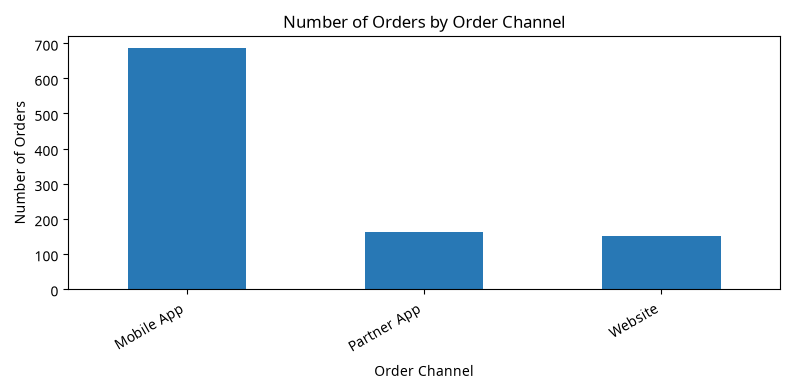

Interpretation: Compare recorded order volume across channels; this chart does not measure channel profitability.


In [37]:
# Task 7.1 — Plot order count by Order Channel
# Plot order counts by channel with a title and labeled axes.
channel_counts = work_df["Order Channel"].dropna().value_counts()
ax = channel_counts.plot(kind="bar", figsize=(8, 4), color="#2878B5")
ax.set_title("Number of Orders by Order Channel")
ax.set_xlabel("Order Channel")
ax.set_ylabel("Number of Orders")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
print("Interpretation: Compare recorded order volume across channels; this chart does not measure channel profitability.")

### Task 7.2 — Plot order count by known Payment Method

Unknown payment methods are excluded from this chart to show the known category mix.

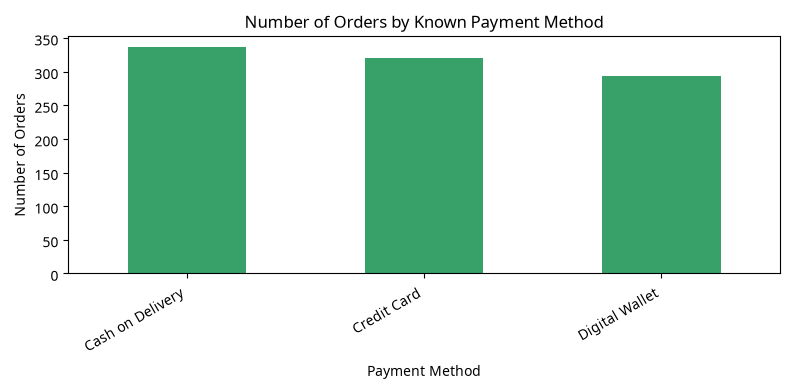

Interpretation: The chart shows the recorded mix of known payment methods; missing methods are not assigned to a real category.


In [38]:
# Task 7.2 — Plot order count by known Payment Method
# Plot known payment method counts with clear labels.
payment_counts = work_df.loc[work_df["Payment Method"].ne("Unknown"), "Payment Method"].value_counts()
ax = payment_counts.plot(kind="bar", figsize=(8, 4), color="#38A169")
ax.set_title("Number of Orders by Known Payment Method")
ax.set_xlabel("Payment Method")
ax.set_ylabel("Number of Orders")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
print("Interpretation: The chart shows the recorded mix of known payment methods; missing methods are not assigned to a real category.")

### Task 7.3 — Plot average valid delivery time by Weather Condition

This optional third chart compares delivery durations by observed weather. The comparison is descriptive, not causal.

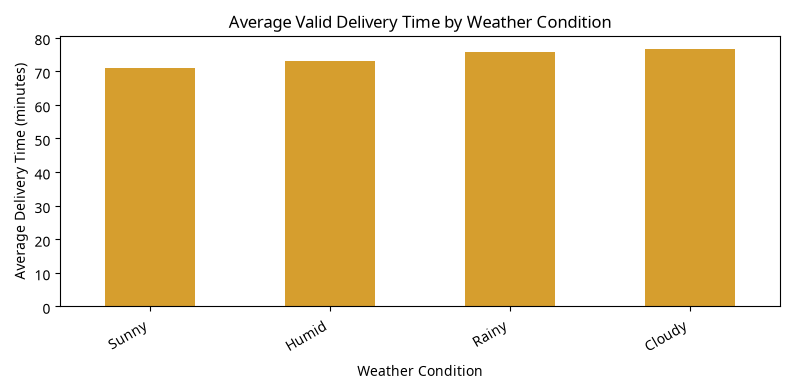

Interpretation: Any differences are associations in this dataset and do not establish that weather caused the difference.


In [39]:
# Task 7.3 — Plot average valid delivery time by Weather Condition
# Compare mean nonnegative delivery duration for each recorded weather category.
weather_delivery = work_df.loc[
    work_df["Delivery_Time_Minutes"].notna() & work_df["Delivery_Time_Minutes"].ge(0)
].groupby("Weather Condition")["Delivery_Time_Minutes"].mean().sort_values()
ax = weather_delivery.plot(kind="bar", figsize=(8, 4), color="#D69E2E")
ax.set_title("Average Valid Delivery Time by Weather Condition")
ax.set_xlabel("Weather Condition")
ax.set_ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
print("Interpretation: Any differences are associations in this dataset and do not establish that weather caused the difference.")

## Task 8 — Validate the transformed dataset

### Task 8.1 — Check that the cleaned dataset has all expected columns

Verify that no required source field has been lost.

In [40]:
# Task 8.1 — Check that the cleaned dataset has all expected columns
# Assert that every source column is still present in the cleaned data.
expected_columns = raw_df.columns.tolist()
missing_expected_columns = [col for col in expected_columns if col not in work_df.columns]
print("Missing expected columns:", missing_expected_columns)
assert not missing_expected_columns
print("Expected source columns check: PASS")

Missing expected columns: []
Expected source columns check: PASS


### Task 8.2 — Validate datetime and financial data types

Confirm datetime fields use datetime dtype and financial fields use numeric dtype.

In [41]:
# Task 8.2 — Validate datetime and financial data types
# Assert that parsed datetime and financial columns have suitable types.
assert all(pd.api.types.is_datetime64_any_dtype(work_df[col]) for col in datetime_columns)
assert all(pd.api.types.is_numeric_dtype(work_df[col]) for col in financial_columns)
print("Datetime columns:", work_df[datetime_columns].dtypes.astype(str).to_dict())
print("Financial columns:", work_df[financial_columns].dtypes.astype(str).to_dict())
print("Type checks: PASS")

Datetime columns: {'Order Date and Time': 'datetime64[us]', 'Delivery Date and Time': 'datetime64[us]'}
Financial columns: {'Order Value': 'Float64', 'Delivery Fee': 'Float64', 'Commission Fee': 'Float64', 'Payment Processing Fee': 'Float64', 'Refunds/Chargebacks': 'Float64'}
Type checks: PASS


### Task 8.3 — Validate exact duplicate handling

Check that no exact source row duplicates remain after the documented removal.

In [42]:
# Task 8.3 — Validate exact duplicate handling
# Count exact duplicate source rows among the cleaned dataset.
remaining_exact_duplicates = int(work_df[expected_columns].duplicated().sum())
print("Remaining exact source-row duplicates:", remaining_exact_duplicates)
assert remaining_exact_duplicates == 0
print("Exact duplicate handling: PASS")

Remaining exact source-row duplicates: 0
Exact duplicate handling: PASS


### Task 8.4 — Check and explain repeated Order IDs

Repeated IDs are reported and not automatically removed by the cleaning rules.

In [43]:
# Task 8.4 — Check and explain repeated Order IDs
# Report repeated source identifiers after exact duplicate removal.
repeated_id_check = work_df.loc[work_df["Order ID"].duplicated(keep=False)].sort_values("Order ID")
print("Rows with repeated Order IDs after exact duplicate removal:", len(repeated_id_check))
display(repeated_id_check.head(10))
print("Decision: retain any repeated IDs unless evidence shows they are duplicate transactions.")

Rows with repeated Order IDs after exact duplicate removal: 0


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Delivery_Time_Minutes,Order_Date,Order_Hour,Platform_Net_Revenue,Invalid_Delivery_Duration,Long_Delivery_Review_Flag


Decision: retain any repeated IDs unless evidence shows they are duplicate transactions.


### Task 8.5 — Validate nonnegative durations and document flagged rows

Exclude negative durations from valid metrics and keep the problematic rows visible for review.

In [44]:
# Task 8.5 — Validate nonnegative durations and document flagged rows
# Verify there are no negative durations in the set classified as valid.
valid_duration_mask = work_df["Delivery_Time_Minutes"].notna() & work_df["Delivery_Time_Minutes"].ge(0)
negative_duration_mask = work_df["Delivery_Time_Minutes"].lt(0)
print("Negative durations flagged:", int(negative_duration_mask.sum()))
assert not (work_df.loc[valid_duration_mask, "Delivery_Time_Minutes"] < 0).any()
display(work_df.loc[negative_duration_mask, ["Order ID", *datetime_columns, "Delivery_Time_Minutes"]])
print("Valid-duration nonnegative check: PASS")

Negative durations flagged: 0


,Order ID,Order Date and Time,Delivery Date and Time,Delivery_Time_Minutes


Valid-duration nonnegative check: PASS


### Task 8.6 — Manually inspect a few delivery-time calculations

Recalculate delivery duration from timestamps for up to five records and compare.

In [45]:
# Task 8.6 — Manually inspect a few delivery-time calculations
# Recalculate duration for a small set of records with both timestamps.
duration_check = work_df.dropna(subset=datetime_columns).head(5).copy()
duration_check["Manual_Duration_Minutes"] = (
    duration_check["Delivery Date and Time"] - duration_check["Order Date and Time"]
).dt.total_seconds() / 60
duration_check["Duration_Matches"] = np.isclose(
    duration_check["Delivery_Time_Minutes"], duration_check["Manual_Duration_Minutes"]
)
display(duration_check[["Order ID", "Delivery_Time_Minutes", "Manual_Duration_Minutes", "Duration_Matches"]])
assert duration_check["Duration_Matches"].all()
print("Manual delivery duration check: PASS")

,Order ID,Delivery_Time_Minutes,Manual_Duration_Minutes,Duration_Matches
0,1,88.0,88.0,True
1,2,35.0,35.0,True
2,3,58.0,58.0,True
3,4,46.0,46.0,True
4,5,89.0,89.0,True


Manual delivery duration check: PASS


### Task 8.7 — Manually inspect the platform revenue formula

Recalculate the formula for up to five complete rows and compare with the derived field.

In [46]:
# Task 8.7 — Manually inspect the platform revenue formula
# Independently recalculate net revenue where all required inputs are present.
revenue_check = work_df.dropna(subset=revenue_inputs).head(5).copy()
revenue_check["Manual_Revenue"] = (
    revenue_check["Commission Fee"] + revenue_check["Delivery Fee"]
    - revenue_check["Payment Processing Fee"] - revenue_check["Refunds/Chargebacks"]
)
revenue_check["Revenue_Matches"] = np.isclose(
    revenue_check["Platform_Net_Revenue"], revenue_check["Manual_Revenue"]
)
display(revenue_check[revenue_inputs + ["Platform_Net_Revenue", "Manual_Revenue", "Revenue_Matches"]])
assert revenue_check["Revenue_Matches"].all()
print("Manual net revenue formula check: PASS")

,Commission Fee,Delivery Fee,Payment Processing Fee,Refunds/Chargebacks,Platform_Net_Revenue,Manual_Revenue,Revenue_Matches
0,150.0,0.0,47.0,0.0,103.0,103.0,True
1,198.0,40.0,23.0,0.0,215.0,215.0,True
2,195.0,30.0,45.0,0.0,180.0,180.0,True
5,92.0,20.0,27.0,150.0,-65.0,-65.0,True
6,144.0,30.0,12.0,50.0,112.0,112.0,True


Manual net revenue formula check: PASS


### Task 8.8 — Compare missing-value counts before and after cleaning

Show both counts using the same original source columns. Category labels may reduce missingness; financial nulls are intentionally retained.

In [47]:
# Task 8.8 — Compare missing-value counts before and after cleaning
# Compare source-field missingness before and after cleaning.
missing_comparison = pd.DataFrame({
    "Before cleaning": raw_df[expected_columns].isna().sum(),
    "After cleaning": work_df[expected_columns].isna().sum(),
})
display(missing_comparison)
print("Missingness comparison complete; remaining financial nulls are intentional.")

,Before cleaning,After cleaning
Order ID,0,0
Customer ID,0,0
Restaurant ID,0,0
Order Date and Time,0,0
Delivery Date and Time,0,0
Order Value,41,40
Delivery Fee,50,50
Payment Method,50,0
Discounts and Offers,242,0
Commission Fee,40,40


Missingness comparison complete; remaining financial nulls are intentional.


### Task 8.9 — Report removed, retained, and calculation-excluded records

These exclusion groups can overlap because one order may be ineligible for more than one metric.

In [48]:
# Task 8.9 — Report removed, retained, and calculation-excluded records
# Report row accounting and records excluded from key calculations.
valid_revenue_mask = work_df["Platform_Net_Revenue"].notna()
print("Original records:", len(raw_df))
print("Removed as exact duplicates:", original_row_count - len(work_df))
print("Retained cleaned records:", len(work_df))
print("Excluded from valid delivery-duration metrics:", int((~valid_duration_mask).sum()))
print("Excluded from revenue metric due to missing component(s):", int((~valid_revenue_mask).sum()))
print("All validation assertions completed successfully.")

Original records: 1010
Removed as exact duplicates: 10
Retained cleaned records: 1000
Excluded from valid delivery-duration metrics: 0
Excluded from revenue metric due to missing component(s): 172
All validation assertions completed successfully.
